# Falla estàtica: disseny paramètric d'un suport de tapa de dipòsit
**Disseny i assaig de màquines** · Màster en Enginyeria Industrial (UdG)

Suport angular de perfil en T, de fosa gris EN-GJL-300 (material fràgil), que aguanta la tapa mòbil d'un dipòsit.

- **Apartat 2):** coeficient de seguretat estàtic de les seccions A i B del disseny inicial, amb el criteri de Coulomb-Mohr modificat.
- **Apartat 3):** redisseny per a diferents distàncies $D$ amb el mètode de la bisecció, mantenint $\mathit{SF}_e \ge 2{,}2$.

Aquest quadern reprodueix l'script `DiAM_tapa_SOL.py` i té la mateixa estructura que `DiAM_tapa_SOL.m`.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

## Funcions emprades
- `calc_eta`: coeficients $\eta_1$ i $\eta_3$ de torsió de seccions rectangulars, per interpolació.
- `s_principals`: tensions principals d'un estat pla de tensions.
- `criteri_MC_mod`: coeficient de seguretat amb el criteri de Coulomb-Mohr modificat.
- `SF_suport`: propietats de la secció, sol·licitacions, tensions als punts A-a, A-b i B-a i coeficient de seguretat (Algorisme 1).
- `biseccio`: mètode de la bisecció sobre l'increment enter $k$ de les variables de disseny (Algorisme 2).

In [2]:
# (en Python s'han de definir abans de cridar-les; en MatLab van al final)

def calc_eta(hb):
    """Coeficients de torsió de seccions rectangulars en funció de h/b."""
    h_b  = [1, 1.5, 2, 2.5, 3, 4, 5, 6, 7, 8, 9, 10, 100]
    eta1 = [1.0, 0.858, 0.796, 0.775, 0.753, 0.743, 0.743, 0.743, 0.743, 0.743, 0.743, 0.743, 0.743]
    eta3 = [0.141, 0.196, 0.229, 0.249, 0.263, 0.281, 0.291, 0.299, 0.303, 0.307, 0.310, 0.313, 0.333]
    return float(np.interp(hb, h_b, eta1)), float(np.interp(hb, h_b, eta3))


def s_principals(s_x, s_y, s_xy):
    """Tensions principals d'un estat pla de tensions (s_x, s_y, s_xy)."""
    s_prin = np.linalg.eigvalsh(np.array([[s_x, s_xy], [s_xy, s_y]]))
    return float(max(s_prin)), float(min(s_prin))


def criteri_MC_mod(S_ut, S_uc, sigmaA, sigmaB):
    """Coeficient de seguretat amb el criteri de Coulomb-Mohr modificat.
    sigmaA = tensió principal major, sigmaB = tensió principal menor."""
    if sigmaA < sigmaB:                       # ordena sigmaA >= sigmaB
        sigmaA, sigmaB = sigmaB, sigmaA
    if sigmaA >= 0 and sigmaB >= 0:
        return S_ut/sigmaA, 'traccio'
    elif sigmaA <= 0 and sigmaB <= 0:
        return S_uc/abs(sigmaB), 'compressio'
    elif abs(sigmaB) <= abs(sigmaA):
        return S_ut/sigmaA, 'traccio'
    else:
        return (S_ut*S_uc)/(S_uc*sigmaA - S_ut*(sigmaA + sigmaB)), 'traccio-compressio'


def SF_suport(D, r_o, a, b, t, de, F, S_ut, S_uc):
    """Coeficient de seguretat estàtic de les seccions A i B del suport.
    Entrada: D, r_o, a, b, t, de [mm], F [N], S_ut, S_uc [MPa]
    Sortida: SF, coeficient de seguretat mínim [-]
             R,  diccionari amb resultats intermedis
    """
    # Propietats de la secció en T de la zona corba
    r_i = r_o - a                                           # radi interior
    A   = b*t + (a - t)*t                                   # àrea
    x_c = (b*t*t/2 + (a - t)*t*(t + (a - t)/2))/A           # centroide des de r_i
    r_c = r_i + x_c                                         # radi del centroide
    r_n = A/(b*math.log((r_i + t)/r_i) + t*math.log(r_o/(r_i + t)))  # línia neutra
    e   = r_c - r_n
    c_i = r_n - r_i
    c_o = r_o - r_n
    I   = b*t**3/12 + b*t*(x_c - t/2)**2 + t*(a - t)**3/12 + (a - t)*t*(t + (a - t)/2 - x_c)**2
    I_p = t*b**3/12 + (a - t)*t**3/12                       # respecte l'eix de simetria
    alpha = 1.1                                             # factor per a seccions en T
    _, eta3_1 = calc_eta(b/t)                               # ala
    _, eta3_2 = calc_eta((a - t)/t)                         # ànima
    I_t = alpha*(eta3_1*b*t**3 + eta3_2*(a - t)*t**3)       # rigidesa a torsió
    M_e = (b - t)/2*t*(x_c - t/2)                           # moment estàtic de mitja ala
    eta1_b, _ = calc_eta(a/t)                               # relació tau(T) punt b / punt a

    # Secció A: sol·licitacions
    M_A = (D - r_i)*F       # N·mm, moment flector
    T_A = de*F              # N·mm, moment torsor
    V_A = F                 # N,    esforç tallant

    # Secció A, punt a: flexió (biga corba) + torsió + tallant
    sAa = M_A*c_i/(A*e*r_i)
    tAa = T_A*t/I_t + V_A*M_e/(t*I)
    s1_Aa, s2_Aa = s_principals(sAa, 0, tAa)
    SF_Aa, _ = criteri_MC_mod(S_ut, S_uc, s1_Aa, s2_Aa)

    # Secció A, punt b: flexió (biga corba) + torsió
    sAb = -M_A*c_o/(A*e*r_o)
    tAb = eta1_b*T_A*t/I_t
    s1_Ab, s2_Ab = s_principals(sAb, 0, tAb)
    SF_Ab, _ = criteri_MC_mod(S_ut, S_uc, s1_Ab, s2_Ab)

    # Secció B: sol·licitacions
    M_B  = (D + x_c)*F      # N·mm, moment flector
    Mp_B = de*F             # N·mm, moment flector degut al descentrament
    N_B  = F                # N,    esforç axial

    # Secció B, punt a: flexió (biga corba) + flexió (biga recta) + axial
    sBa = M_B*c_i/(A*e*r_i) + Mp_B*(b/2)/I_p + N_B/A
    SF_Ba, _ = criteri_MC_mod(S_ut, S_uc, sBa, 0)

    # Coeficient de seguretat mínim
    SF = min(SF_Aa, SF_Ab, SF_Ba)

    R = dict(A=A, x_c=x_c, r_n=r_n, e=e, I=I, I_p=I_p, I_t=I_t, M_e=M_e,
             sAa=sAa, tAa=tAa, s1_Aa=s1_Aa, s2_Aa=s2_Aa, SF_Aa=SF_Aa,
             sAb=sAb, tAb=tAb, s1_Ab=s1_Ab, s2_Ab=s2_Ab, SF_Ab=SF_Ab,
             sBa=sBa, SF_Ba=SF_Ba)
    return SF, R


def biseccio(D, r_o0, a0, b, t, de, F, S_ut, S_uc, SF_d, pas, k_min, k_max):
    """Mètode de la bisecció sobre l'increment enter k (múltiples de pas).
    Hipòtesi: SF(k_min) < SF_d i SF(k_max) >= SF_d.
    Retorna el k mínim que compleix SF >= SF_d i el nombre d'iteracions.
    """
    k_lo, k_hi, cont = k_min, k_max, 0
    while (k_hi - k_lo) > 1:
        cont += 1
        k = (k_lo + k_hi)//2                        # punt mig
        SF, _ = SF_suport(D, r_o0 + k*pas, a0 + k*pas, b, t, de, F, S_ut, S_uc)
        if SF >= SF_d:
            k_hi = k                                # compleix: es pot reduir
        else:
            k_lo = k                                # no compleix: cal augmentar
    return k_hi, cont

## Dades del problema
Especificacions del cas i paràmetres del redisseny.

In [3]:
# Material [MPa]
S_ut = 300.0    # resistència a tracció
S_uc = 780.0    # resistència a compressió
# Càrrega [N] i excentricitat [mm]
F  = 10e3       # força aplicada al centre del dipòsit
de = 20.0       # descentrament lateral màxim de la força
# Geometria [mm]
D0   = 180.0    # distància de l'eix del dipòsit al suport (disseny inicial)
r_o0 = 120.0    # radi exterior de la corba (variable de disseny)
a0   = 80.0     # cantell de la secció en T (variable de disseny)
b    = 70.0     # amplada de l'ala de la T (constant)
t    = 8.0      # gruix de l'ala i de l'ànima (constant)
# Redisseny (apartat 3)
SF_d  = 2.2                                 # coeficient de seguretat mínim exigit
D3    = np.array([240., 300., 360., 420.])  # mm, noves distàncies D
pas   = 5.0                                 # mm, increment de les variables de disseny
k_min = -10                                 # increment mínim (k_min*pas = -50 mm)
k_max = 16                                  # increment màxim (k_max*pas = 80 mm)

## Apartat 1): criteri de falla
El criteri emprat a l'apèndix és el de **Coulomb-Mohr modificat**. És adequat per a una fosa gris, que és un material fràgil, sense fluència apreciable i amb una resistència a compressió molt més gran que a tracció ($S_{uc}/S_{ut} = 2{,}6$).

## Apartat 2): disseny inicial
Coeficient de seguretat de les seccions A i B amb les cotes del croquis ($D = 180$ mm, $r_o = 120$ mm, $a = 80$ mm).

In [4]:
SF0, R0 = SF_suport(D0, r_o0, a0, b, t, de, F, S_ut, S_uc)

print(f"Apartat 2): D = {D0:.0f} mm, r_o = {r_o0:.0f} mm, a = {a0:.0f} mm")
print(f"  A = {R0['A']:.0f} mm^2, x_c = {R0['x_c']:.2f} mm, "
      f"r_n = {R0['r_n']:.2f} mm, e = {R0['e']:.2f} mm")
print(f"  I = {R0['I']:.3g} mm^4, I' = {R0['I_p']:.3g} mm^4, "
      f"I_t = {R0['I_t']:.0f} mm^4, M_e = {R0['M_e']:.0f} mm^3")
print(f"  Secció A, punt a: sigma = {R0['sAa']:5.1f}, tau = {R0['tAa']:5.1f}, "
      f"sigma_A = {R0['s1_Aa']:6.1f}, sigma_B = {R0['s2_Aa']:6.1f} MPa -> SF = {R0['SF_Aa']:.2f}")
print(f"  Secció A, punt b: sigma = {R0['sAb']:5.1f}, tau = {R0['tAb']:5.1f}, "
      f"sigma_A = {R0['s1_Ab']:6.1f}, sigma_B = {R0['s2_Ab']:6.1f} MPa -> SF = {R0['SF_Ab']:.2f}")
print(f"  Secció B, punt a: sigma = {R0['sBa']:5.1f} MPa -> SF = {R0['SF_Ba']:.2f}")
print(f"  SF de les seccions A i B = {SF0:.2f}\n")

Apartat 2): D = 180 mm, r_o = 120 mm, a = 80 mm
  A = 1136 mm^2, x_c = 24.28 mm, r_n = 56.54 mm, e = 7.74 mm
  I = 7.06e+05 mm^4, I' = 2.32e+05 mm^4, I_t = 24762 mm^4, M_e = 5030 mm^3
  Secció A, punt a: sigma =  65.8, tau =  73.5, sigma_A =  113.4, sigma_B =  -47.6 MPa -> SF = 2.64
  Secció A, punt b: sigma = -84.2, tau =  48.0, sigma_A =   21.8, sigma_B = -105.9 MPa -> SF = 5.54
  Secció B, punt a: sigma = 135.0 MPa -> SF = 2.22
  SF de les seccions A i B = 2.22



## Apartat 3): redisseny per a diferents $D$
Les variables de disseny augmenten simultàniament $k\,\Delta$: $a = a_0 + k\,\Delta$ i $r_o = r_{o,0} + k\,\Delta$. La bisecció es fa directament sobre l'enter $k$, de manera que s'obté el disseny més lleuger que compleix $\mathit{SF}_e \ge \mathit{SF}_d$. Com a comprovació, també s'aplica el mètode incremental.

In [5]:
# Les variables de disseny augmenten simultàniament k*pas: a = a0 + k*pas,
# r_o = r_o0 + k*pas (el radi interior r_i = r_o - a no canvia).
k3  = np.zeros(len(D3), dtype=int)
n3  = np.zeros(len(D3), dtype=int)
SF3 = np.zeros(len(D3))
print("Apartat 3): mètode de la bisecció")
for i, D in enumerate(D3):
    k3[i], n3[i] = biseccio(D, r_o0, a0, b, t, de, F, S_ut, S_uc,
                            SF_d, pas, k_min, k_max)
    SF3[i], _ = SF_suport(D, r_o0 + k3[i]*pas, a0 + k3[i]*pas, b, t, de, F, S_ut, S_uc)
    print(f"  D = {D:.0f} mm: {n3[i]} iteracions, r_o = {r_o0 + k3[i]*pas:.0f} mm, "
          f"a = {a0 + k3[i]*pas:.0f} mm, SF = {SF3[i]:.2f}")

# Comprovació amb el mètode incremental (augmentar k d'un en un)
print("\nComprovació: mètode incremental")
for D in D3:
    k = k_min
    SF_trial, _ = SF_suport(D, r_o0 + k*pas, a0 + k*pas, b, t, de, F, S_ut, S_uc)
    cont = 0
    while SF_trial < SF_d:
        cont += 1
        k += 1
        SF_trial, _ = SF_suport(D, r_o0 + k*pas, a0 + k*pas, b, t, de, F, S_ut, S_uc)
    print(f"  D = {D:.0f} mm: {cont} iteracions, r_o = {r_o0 + k*pas:.0f} mm, "
          f"a = {a0 + k*pas:.0f} mm, SF = {SF_trial:.2f}")

Apartat 3): mètode de la bisecció
  D = 240 mm: 4 iteracions, r_o = 140 mm, a = 100 mm, SF = 2.28
  D = 300 mm: 4 iteracions, r_o = 155 mm, a = 115 mm, SF = 2.24
  D = 360 mm: 4 iteracions, r_o = 170 mm, a = 130 mm, SF = 2.22
  D = 420 mm: 5 iteracions, r_o = 185 mm, a = 145 mm, SF = 2.21

Comprovació: mètode incremental
  D = 240 mm: 14 iteracions, r_o = 140 mm, a = 100 mm, SF = 2.28
  D = 300 mm: 17 iteracions, r_o = 155 mm, a = 115 mm, SF = 2.24
  D = 360 mm: 20 iteracions, r_o = 170 mm, a = 130 mm, SF = 2.22
  D = 420 mm: 23 iteracions, r_o = 185 mm, a = 145 mm, SF = 2.21


## Representació gràfica de la solució

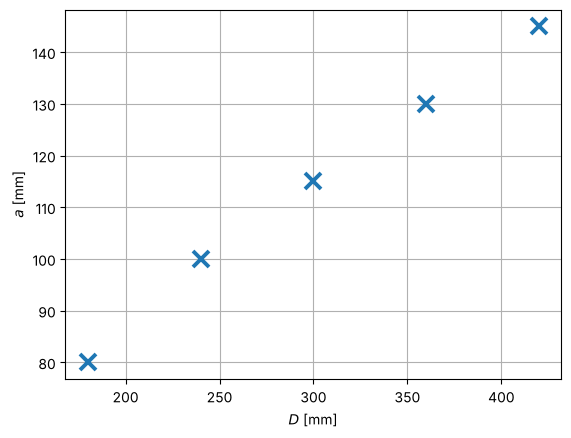

In [6]:
plt.figure()
plt.grid(True)
plt.plot(np.r_[D0, D3], np.r_[a0, a0 + k3*pas], 'x', markersize=12, markeredgewidth=2.8)
plt.xlabel(r'$D$ [mm]')
plt.ylabel(r'$a$ [mm]')
plt.savefig('Fig_DiAM_biga_T.pdf', bbox_inches='tight')
plt.show()

## Discussió
El cantell necessari creix de manera pràcticament lineal amb la distància $D$: a partir de $D = 240$ mm, cada increment de 60 mm requereix augmentar el cantell 15 mm. El primer salt (de 180 a 240 mm) és de 20 mm perquè la resolució de 5 mm obliga a un disseny amb un coeficient de seguretat clarament superior al requerit. En tots els casos el punt crític és el punt a de la secció B.

La bisecció arriba a la solució amb 4 o 5 avaluacions de la funció, mentre que el mètode incremental en necessita entre 14 i 23.